# Point Kinetics of BWXT-inspired NTP

In [2]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Reactor Parameters

In [ ]:
Lambda = 2e-4 # # prompt neutron lifetime [s]
nu_total = 2.432
nu_d = 0.01668
beta_total = nu_d/nu_total
nu_g = np.array([0.038, 0.213, 0.188, 0.407, 0.128, 0.026])
betas = beta_total*nu_g
T_12_g = np.array([54.51, 21.84, 6, 2.23, 0.496, 0.179])    
lambdas = np.log(2)/T_12_g 

In [90]:
P0 = 250 #MWth

## Analytical Solution (no Delayed)

In [ ]:
rhos = beta_total*np.array([-1, 0, 1])
def P(t,rho):
    ''' '''
    return P0*np.exp(rho*t/Lambda)

In [73]:
t = np.linspace(0, 50e-3, 100)  # time array
P_0 = []
P_1 = []
P_2 = []
for time in t:
    P_0.append(P(time, rhos[0]))
    P_1.append(P(time, rhos[1]))
    P_2.append(P(time, rhos[2]))

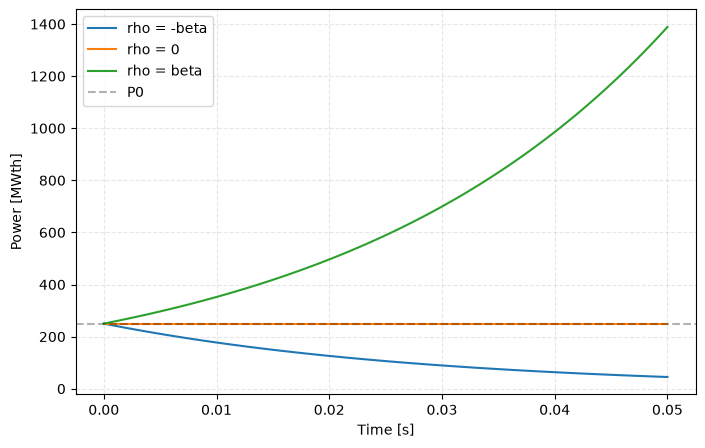

In [78]:
fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(t, P_0, label='rho = -beta')
plt.plot(t, P_1, label='rho = 0')
plt.plot(t, P_2, label='rho = beta')
#plt.ylim(-10, 500)
plt.grid(alpha=0.3, linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('Power [MWth]')
#plt.yscale('log')
ax.axhline(y=250, color='k', linestyle='--', label='P0', alpha=0.3)
plt.legend()

## Analytical Solution (1 Effective DNP Group)

In [85]:
lambda_eff = np.average(lambdas, weights=nu_g)  # effective decay constant

In [86]:
def find_s(rho):
    ''' '''
    a = 1
    b = lambda_eff+(beta_total-rho)/Lambda
    c = -lambda_eff*rho/Lambda
    delta = b**2 - 4*a*c
    if delta < 0:
        return None  # No real roots
    s1 = (-b + np.sqrt(delta)) / (2*a)
    s2 = (-b - np.sqrt(delta)) / (2*a)
    return s1, s2
def P2(rho):
    ''' '''
    s1, s2 = find_s(rho)
    return P0*(s1-rho/Lambda)/(s1-s2)
def P1(rho):
    return P0 - P2(rho)

In [87]:
def P(t, rho):
    ''' '''
    s1, s2 = find_s(rho)
    P1_0 = P1(rho)
    P2_0 = P2(rho)
    return P1_0*np.exp(s1*t) + P2_0*np.exp(s2*t)

In [88]:
rhos = beta_total*np.array([-0.9, -0.01, 0, 0.01, 0.9])

In [142]:
t = np.logspace(-4, 2.5, 500)  # time array
#t = np.linspace(0, 50e-3, 100)  # time array

In [139]:
P_0 = []
P_1 = []
P_2 = []
P_3 = []
P_4 = []
for time in t:
    P_0.append(P(time, rhos[0]))
    P_1.append(P(time, rhos[1]))
    P_2.append(P(time, rhos[2]))
    P_3.append(P(time, rhos[3]))
    P_4.append(P(time, rhos[4]))

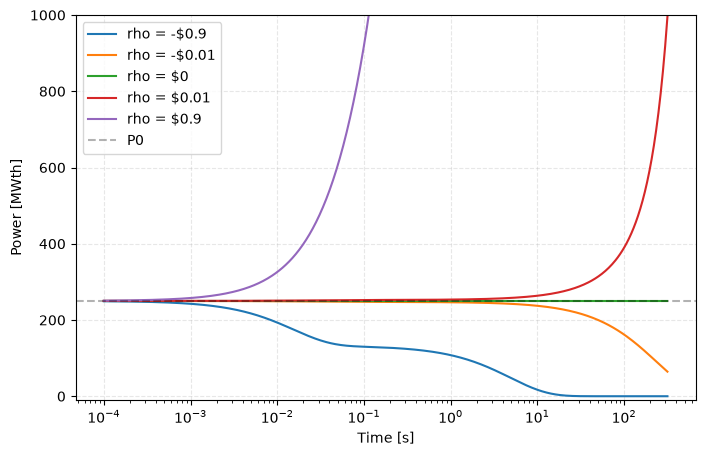

In [144]:
fig, ax = plt.subplots(figsize=(8, 5))
plt.plot(t, P_0, label='rho = -$0.9')
plt.plot(t, P_1, label='rho = -$0.01')
plt.plot(t, P_2, label='rho = $0')
plt.plot(t, P_3, label='rho = $0.01')
plt.plot(t, P_4, label='rho = $0.9')

plt.ylim(-10, 1000)
plt.grid(alpha=0.3, linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('Power [MWth]')
plt.xscale('log')
#plt.yscale('log')

ax.axhline(y=250, color='k', linestyle='--', label='P0', alpha=0.3)
plt.legend()

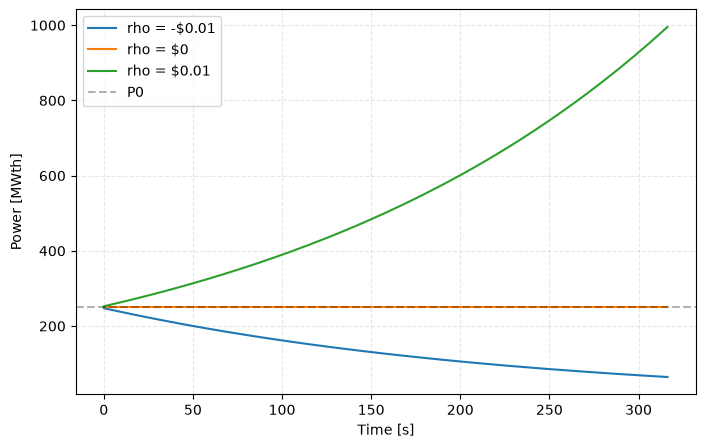

In [147]:
fig, ax = plt.subplots(figsize=(8, 5))
#plt.plot(t, P_0, label='rho = -0.9*beta')
plt.plot(t, P_1, label='rho = -$0.01')
plt.plot(t, P_2, label='rho = $0')
plt.plot(t, P_3, label='rho = $0.01')
#plt.plot(t, P_4, label='rho = $0.9')

#plt.ylim(-10, 500)
plt.grid(alpha=0.3, linestyle='--')
plt.xlabel('Time [s]')
plt.ylabel('Power [MWth]')
#plt.xscale('log')
ax.axhline(y=250, color='k', linestyle='--', label='P0', alpha=0.3)
plt.legend()

## Numerical Solution

In [150]:
def pke_rhs(t, y, rho, beta_total, Lambda, betas, lambdas):
    n = y[0]
    C = y[1:]
    dn_dt = ((rho - beta_total) / Lambda) * n + np.sum(lambdas * C)
    dC_dt = (betas / Lambda) * n - lambdas * C
    return np.concatenate(([dn_dt], dC_dt))

### Initial Conditions and Solver Execution

In [176]:
n0 = 250
C0 = betas * n0 / (Lambda * lambdas)
y0 = np.concatenate(([n0], C0))
t_span = (0, 10.0)
t_eval = np.linspace(*t_span, 1000)

sol0 = solve_ivp(
    pke_rhs, t_span, y0, t_eval=t_eval, method='Radau',
    args=(rhos[0], beta_total, Lambda, betas, lambdas)
)
sol1 = solve_ivp(
    pke_rhs, t_span, y0, t_eval=t_eval, method='Radau',
    args=(rhos[1], beta_total, Lambda, betas, lambdas)
)
sol2 = solve_ivp(
    pke_rhs, t_span, y0, t_eval=t_eval, method='Radau',
    args=(rhos[2], beta_total, Lambda, betas, lambdas)
)
sol3 = solve_ivp(
    pke_rhs, t_span, y0, t_eval=t_eval, method='Radau',
    args=(rhos[3], beta_total, Lambda, betas, lambdas)
)
sol4 = solve_ivp(
    pke_rhs, t_span, y0, t_eval=t_eval, method='Radau',
    args=(rhos[4], beta_total, Lambda, betas, lambdas)
)

## Plot Reactor Power

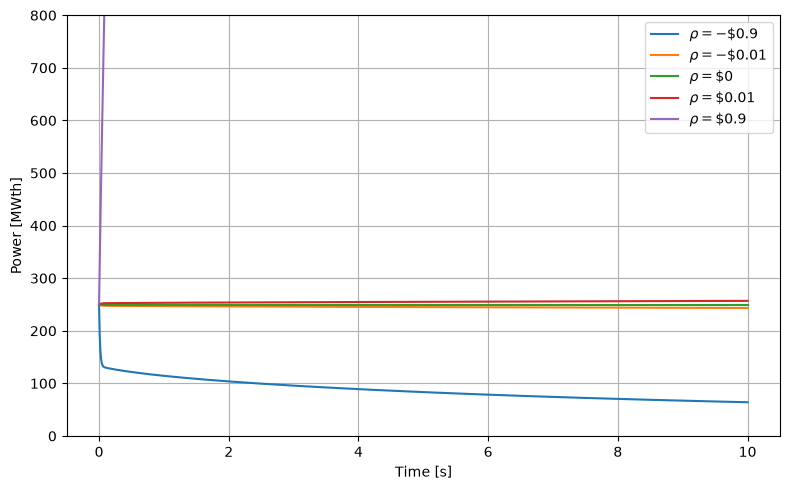

In [183]:
plt.figure(figsize=(8, 5))
plt.plot(sol0.t, sol0.y[0], label=r'$\rho = -\$0.9$')
plt.plot(sol1.t, sol1.y[0], label=r'$\rho = -\$0.01$')
plt.plot(sol2.t, sol2.y[0], label=r'$\rho = \$0$')
plt.plot(sol3.t, sol3.y[0], label=r'$\rho = \$0.01$')
plt.plot(sol4.t, sol4.y[0], label=r'$\rho = \$0.9$')
plt.xlabel('Time [s]')
plt.ylabel('Power [MWth]')
#plt.title('Power Response to Step Reactivity')
plt.grid(True)
plt.legend()
plt.ylim(-1, 800)
#plt.xscale('log')
plt.tight_layout()
plt.show()

## Plot Delayed Neutron Precursor Concentrations

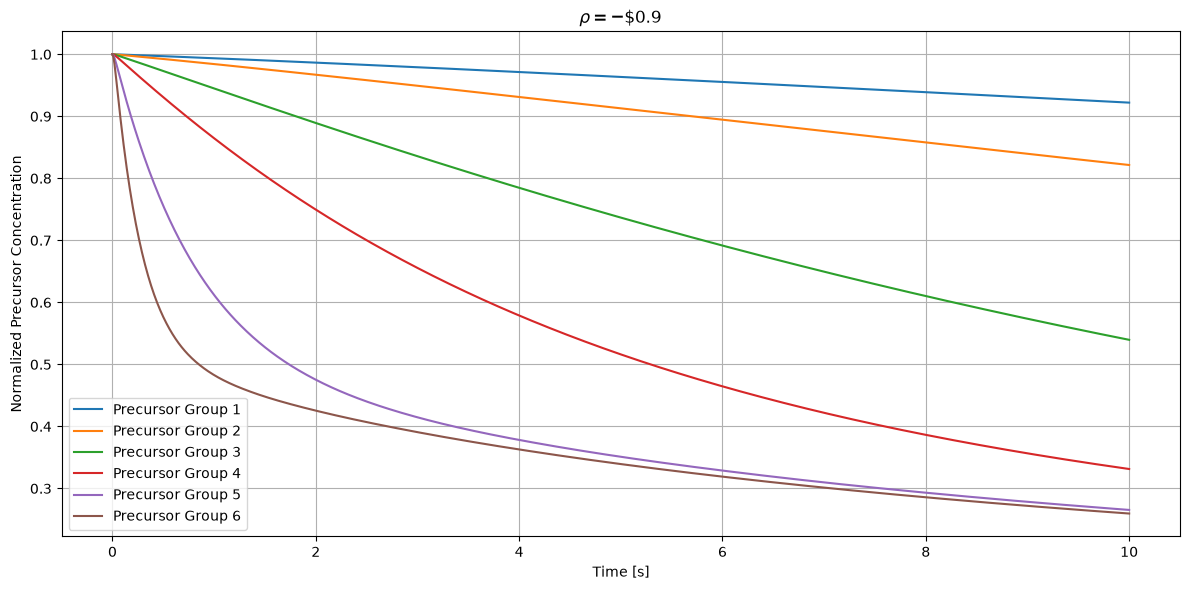

In [202]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.plot(sol0.t, sol0.y[i + 1]/ sol0.y[i + 1][0], label=f'Precursor Group {i + 1}')
plt.xlabel('Time [s]')
plt.ylabel('Normalized Precursor Concentration')
plt.title(r'$\rho=-\$0.9$')
plt.grid(True)
#plt.xscale('log')
#plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

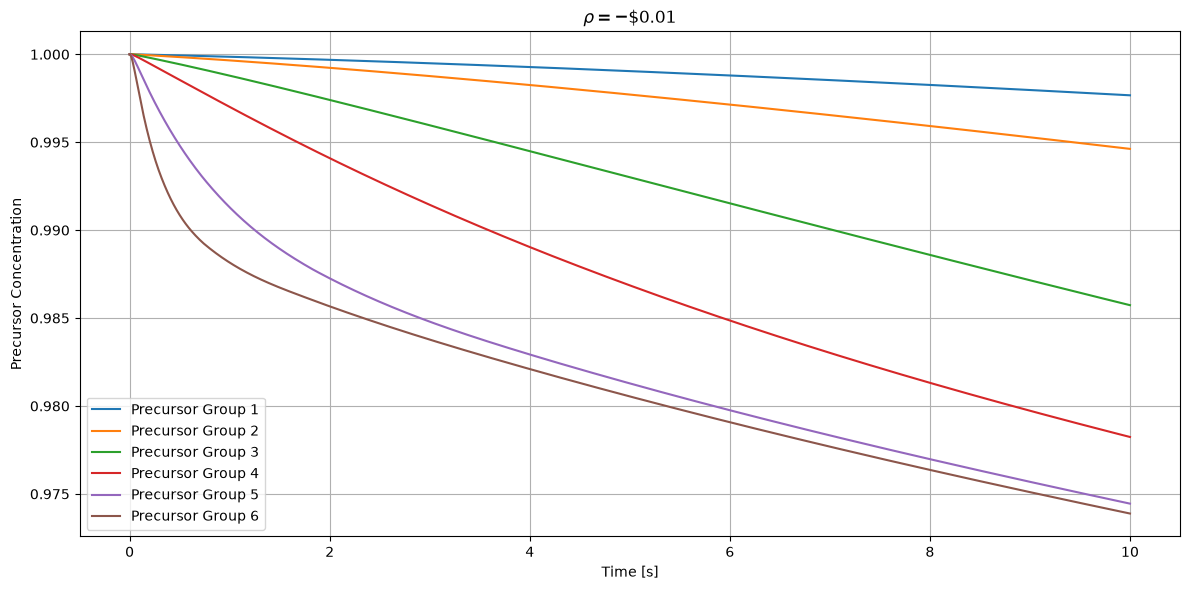

In [ ]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.plot(sol1.t, sol1.y[i + 1]/ sol1.y[i + 1][0], label=f'Precursor Group {i + 1}')
plt.xlabel('Time [s]')
plt.ylabel('Normalized Precursor Concentration')
plt.title(r'$\rho=-\$0.01$')
plt.grid(True)
#plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()

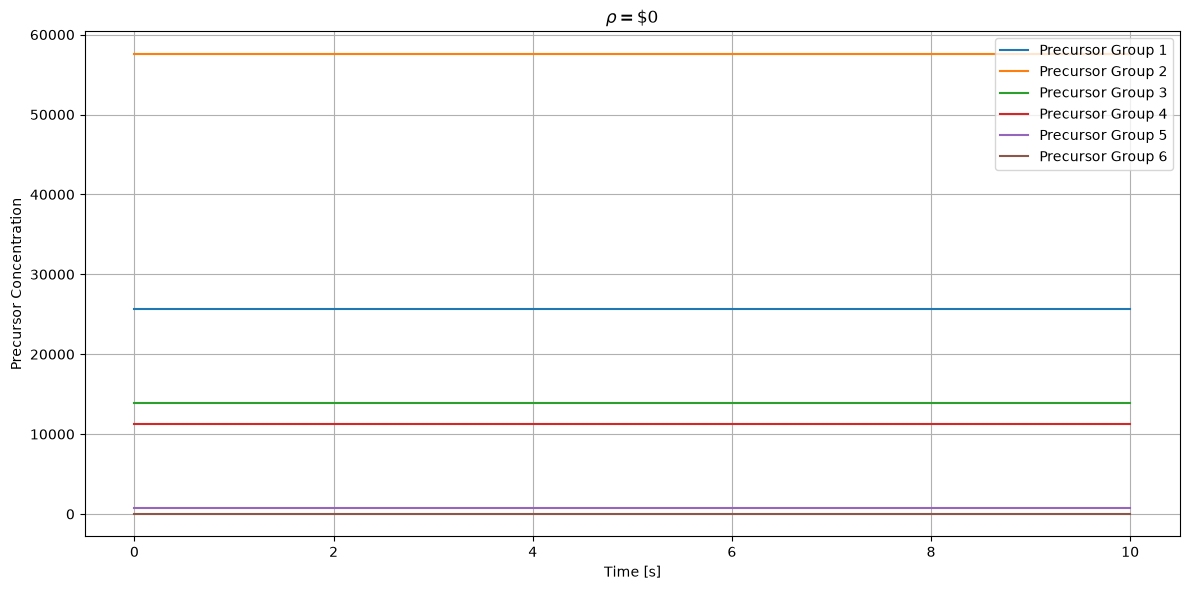

In [203]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.plot(sol2.t, sol2.y[i + 1], label=f'Precursor Group {i + 1}')
plt.xlabel('Time [s]')
plt.ylabel('Precursor Concentration')
plt.title(r'$\rho=\$0$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

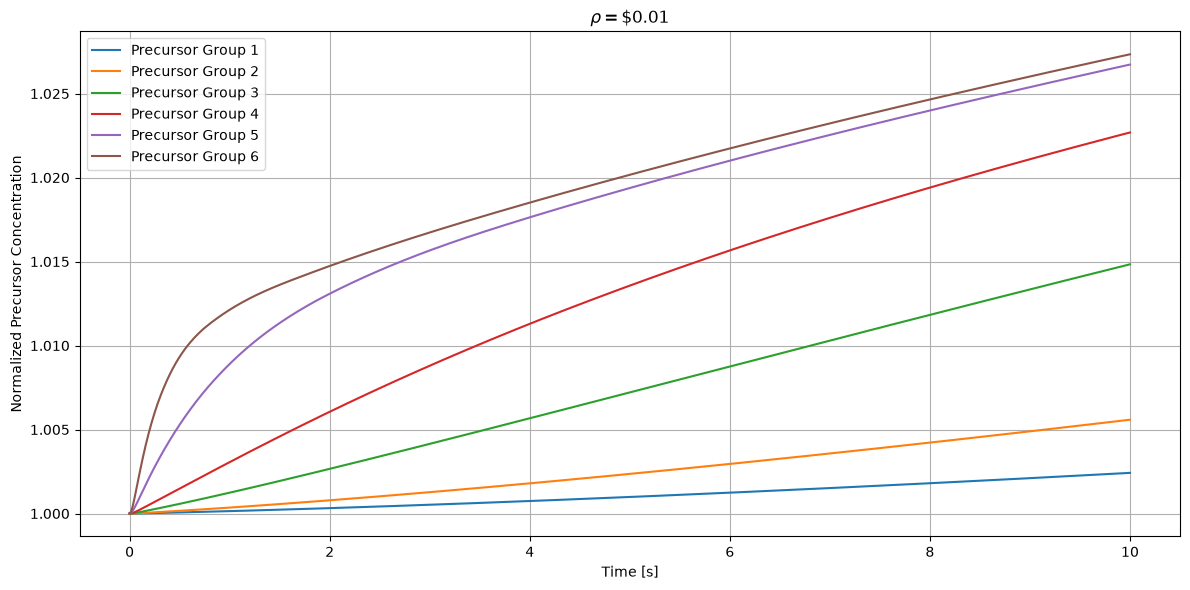

In [204]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.plot(sol3.t, sol3.y[i + 1]/ sol3.y[i + 1][0], label=f'Precursor Group {i + 1}')
plt.xlabel('Time [s]')
plt.ylabel('Normalized Precursor Concentration')
plt.title(r'$\rho=\$0.01$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

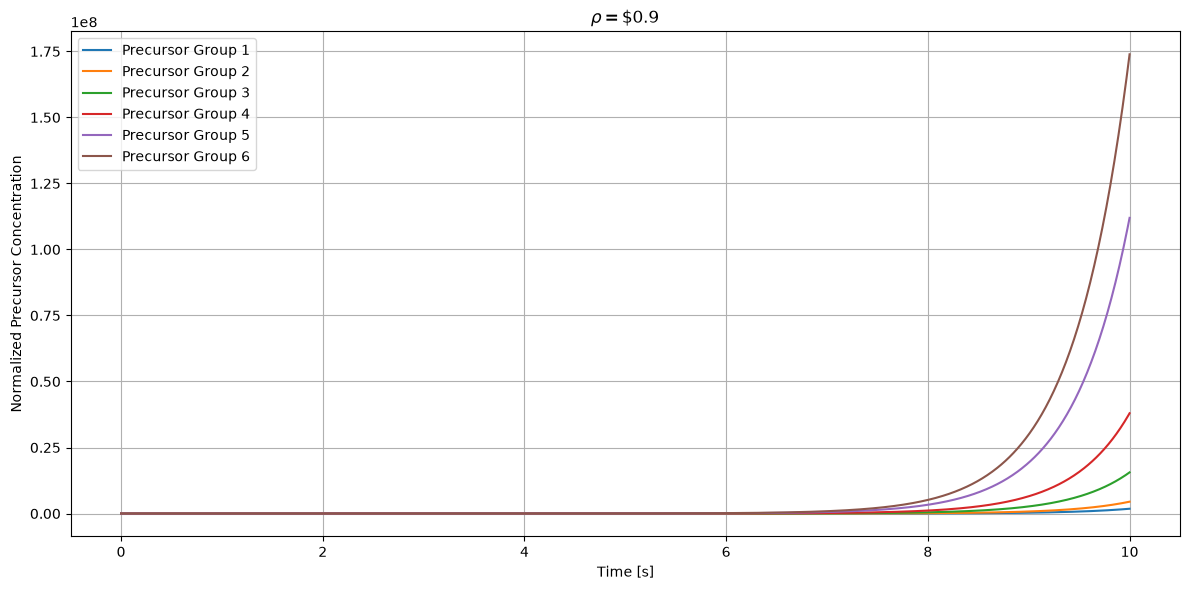

In [205]:
plt.figure(figsize=(12, 6))
for i in range(6):
    plt.plot(sol4.t, sol4.y[i + 1]/ sol4.y[i + 1][0], label=f'Precursor Group {i + 1}')
plt.xlabel('Time [s]')
plt.ylabel('Normalized Precursor Concentration')
plt.title(r'$\rho=\$0.9$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()